# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Ridwanansyah Rahman
- **Email:** muh.ridwanansyah.rahman230806@gmail.com
- **ID Dicoding:** muh_ridwanansyah_r

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada musim apa rata-rata jumlah penyewaan sepeda harian paling tinggi dan paling rendah selama periode 2011-2012, dan berapa selisih rata-ratanya, sehingga operator dapat menyesuaikan jumlah sepeda yang disiapkan pada setiap musim?
- **Pertanyaan 2:** Pada jam berapa rata-rata jumlah penyewaan sepeda per jam paling tinggi pada hari kerja dibandingkan hari libur selama periode 2011-2012, dan berapa selisih rata-ratanya, sehingga operator dapat menjadwalkan distribusi dan perawatan sepeda di luar jam sibuk?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load dataset day.csv and hour.csv

In [2]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
day_df.shape

(731, 16)

In [5]:
day_df.shape

(731, 16)

**Insight:**
- `day_df` berisi 731 baris dan 16 kolom (satu baris per hari), sedangkan `hour_df` berisi 17.379 baris dan 17 kolom (satu baris per jam). Selisih satu kolom adalah `hr` (jam 0-23) yang hanya ada pada `hour_df`.
- Kolom `cnt` adalah total penyewaan, sedangkan `casual` dan `registered` memisahkannya berdasarkan jenis pengguna.
- Beberapa kolom (`season`, `yr`, `mnth`, `weekday`, `weathersit`, `holiday`, `workingday`) masih berupa kode angka, dan kolom cuaca (`temp`, `atemp`, `hum`, `windspeed`) bernilai 0-1.
- Kedua file tidak digabung karena granularitasnya berbeda: `day_df` dipakai untuk analisis per musim dan `hour_df` untuk analisis per jam.

### Assessing Data

#### Memeriksa Tipe Data, Missing Value, Duplikat, Nilai Tidak Wajar dan konsistensi data

In [6]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [7]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [8]:
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [9]:
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [10]:
day_df.duplicated().sum()

np.int64(0)

In [11]:
hour_df.duplicated().sum()

np.int64(0)

In [12]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [13]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [14]:
(day_df['cnt'] != day_df['casual'] + day_df['registered']).sum()

np.int64(0)

In [15]:
(hour_df['cnt'] != hour_df['casual'] + hour_df['registered']).sum()

np.int64(0)

In [16]:
pd.crosstab(day_df['weekday'], day_df['workingday'])

workingday,0,1
weekday,,
0,105,0
1,15,90
2,1,103
3,1,103
4,2,102
5,2,102
6,105,0


In [17]:
pd.crosstab(day_df['holiday'], day_df['workingday'])

workingday,0,1
holiday,,
0,210,500
1,21,0


##### Masalah 1: kolom `dteday` bertipe teks (object), bukan tanggal

In [18]:
day_df['dteday'].dtype
hour_df['dteday'].dtype

dtype('O')

##### Masalah 2: label `season` pada Readme tidak sesuai data

In [19]:
pd.crosstab(day_df['mnth'], day_df['season'])

season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


In [20]:
day_df.groupby('season')['cnt'].mean().round(0)

,cnt
season,
1,2604.0
2,4992.0
3,5644.0
4,4728.0


##### Masalah 3: kolom kategori berupa kode angka

In [21]:
day_df[['season', 'yr', 'mnth', 'weekday', 'weathersit', 'holiday', 'workingday']].dtypes

,0
season,int64
yr,int64
mnth,int64
weekday,int64
weathersit,int64
holiday,int64
workingday,int64


In [22]:
day_df[['season', 'yr', 'weekday', 'weathersit', 'holiday', 'workingday']].nunique()

,0
season,4
yr,2
weekday,7
weathersit,3
holiday,2
workingday,2


In [23]:
pd.crosstab(pd.to_datetime(day_df['dteday']).dt.year, day_df['yr'])

yr,0,1
dteday,,
2011,365,0
2012,0,366


In [24]:
pd.crosstab(pd.to_datetime(day_df['dteday']).dt.day_name(), day_df['weekday'])

weekday,0,1,2,3,4,5,6
dteday,,,,,,,
Friday,0,0,0,0,0,104,0
Monday,0,105,0,0,0,0,0
Saturday,0,0,0,0,0,0,105
Sunday,105,0,0,0,0,0,0
Thursday,0,0,0,0,104,0,0
Tuesday,0,0,104,0,0,0,0
Wednesday,0,0,0,104,0,0,0


##### Masalah 4: kolom cuaca bernilai 0-1 (ternormalisasi)

In [25]:
day_df[['temp', 'atemp', 'hum', 'windspeed']].describe()

,temp,atemp,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.474354,0.627894,0.190486
std,0.183051,0.162961,0.142429,0.077498
min,0.059130,0.079070,0.000000,0.022392
25%,0.337083,0.337842,0.520000,0.134950
50%,0.498333,0.486733,0.626667,0.180975
75%,0.655417,0.608602,0.730209,0.233214
max,0.861667,0.840896,0.972500,0.507463


In [26]:
(day_df['temp'] * 41).describe()

,temp
count,731.000000
mean,20.310776
std,7.505091
min,2.424346
25%,13.820424
50%,20.431653
75%,26.872076
max,35.328347


##### Masalah 5: kelembapan (`hum`) bernilai 0 yang tidak wajar

In [27]:
(day_df['hum'] == 0).sum()

np.int64(1)

In [28]:
(hour_df['hum'] == 0).sum()

np.int64(22)

In [29]:
day_df.loc[day_df['hum'] == 0, ['dteday', 'hum', 'cnt']]

,dteday,hum,cnt
68,2011-03-10,0.0,623


In [30]:
hour_df.loc[hour_df['hum'] == 0, 'dteday'].nunique()

1

In [31]:
hour_df.loc[hour_df['hum'] == 0, 'dteday'].unique()

array(['2011-03-10'], dtype=object)

##### Masalah 6: terdapat jam yang tidak tercatat pada `hour_df`

In [32]:
day_df.shape[0] * 24


17544

In [33]:
hour_df.shape[0]

17379

In [34]:
day_df.shape[0] * 24 - hour_df.shape[0]

165

In [35]:
jam_per_hari = hour_df.groupby('dteday')['hr'].count()
(jam_per_hari == 24).sum()

np.int64(655)

In [36]:
(jam_per_hari < 24).sum()

np.int64(76)

In [37]:
kekurangan_per_jam = day_df.shape[0] - hour_df['hr'].value_counts().sort_index()
kekurangan_per_jam.loc[0:5].sum()

np.int64(110)

In [38]:
kekurangan_per_jam.loc[0:5].sum() / kekurangan_per_jam.sum() * 100

np.float64(66.66666666666666)

In [39]:
kekurangan_per_jam.loc[[8, 17, 18]]

,count
hr,
8,4
17,1
18,3


In [40]:
selisih_cnt = day_df.set_index('dteday')['cnt'] - hour_df.groupby('dteday')['cnt'].sum()
selisih_cnt.abs().sum()

np.int64(0)

##### Masalah 7: outlier pada jumlah penyewaan per jam

In [41]:
q1, q3 = hour_df['cnt'].quantile([0.25, 0.75])
outlier_hour = hour_df[hour_df['cnt'] > q3 + 1.5 * (q3 - q1)]
len(outlier_hour)

505

In [42]:
outlier_hour['hr'].isin([8, 17, 18]).sum()

np.int64(409)

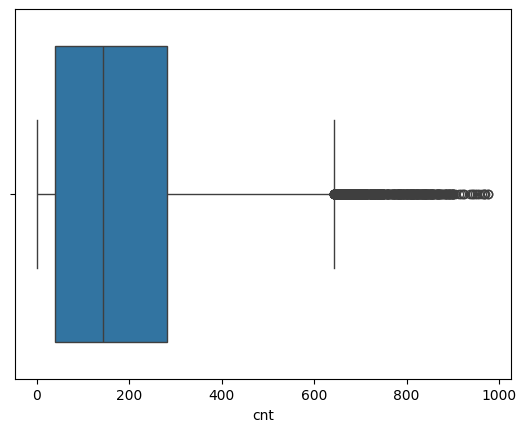

In [43]:
sns.boxplot(x=hour_df['cnt'])
plt.show()

##### Masalah 8: kategori `weathersit` = 4 hanya ada pada `hour_df`

In [44]:
day_df['weathersit'].value_counts().sort_index()

,count
weathersit,
1,463
2,247
3,21


In [45]:
hour_df['weathersit'].value_counts().sort_index()

,count
weathersit,
1,11413
2,4544
3,1419
4,3


**Steps to Take:**
1. **Tipe data:** ubah `dteday` pada `day_df` dan `hour_df` dari `object` menjadi tipe tanggal (`datetime`). *(Masuk Cleaning)*
2. **Label season:** Readme menyebut 1 = springer, 2 = summer, 3 = fall, 4 = winter, tetapi kode 1 pada data jatuh pada Desember-Maret. Label dibuat mengikuti data: 1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall. *(Masuk tahap Cleaning)*
3. **Kolom berkode:** ubah kode `yr` (0 = 2011, 1 = 2012), `mnth`, `weekday`, `weathersit`, `holiday`, dan `workingday` menjadi label teks. Pemetaan `yr` dan `weathersit` mengikuti Readme, sedangkan `weekday` dibuktikan dari data (0 = Sunday sampai 6 = Saturday). *(Masuk tahap Cleaning)*
4. **Kolom cuaca ternormalisasi:** `temp`, `atemp`, `hum`, dan `windspeed` bernilai 0-1. Kembalikan ke skala asli sesuai Readme (`temp` × 41, `atemp` × 50, `hum` × 100, `windspeed` × 67). Hasil `temp` berkisar 2,4-35,3 °C, wajar untuk Washington D.C. *(Masuk tahap Cleaning)*
5. **hum = 0:** terdapat 1 baris pada `day_df` dan 22 baris pada `hour_df`, semuanya berasal dari satu tanggal yang sama, yaitu 2011-03-10. Kelembapan 0% selama satu hari penuh tidak wajar sehingga diduga kegagalan pencatatan sensor. Nilai 0 diganti menjadi kosong (`NaN`), lalu diisi dengan interpolasi dari hari/jam di sekitarnya. *(Masuk Tahap Cleaning)*
6. **Jam tidak tercatat (165 jam):** `hour_df` kekurangan 165 jam dari 17.544 jam ideal (76 hari tidak lengkap, 655 hari lengkap). Sekitar 67% jam yang hilang (110 dari 165) berada pada dini hari (jam 0-5), sedangkan jam sibuk hampir tidak terdampak. Total penyewaan harian pada `day_df` sama dengan jumlah per jam pada `hour_df` (selisih 0), sehingga jam yang hilang kemungkinan adalah jam tanpa penyewaan. Tidak diisi karena tidak ada informasi pasti, cukup dicatat sebagai keterbatasan terutama pada rata-rata penyewaan dini hari.
7. **Outlier:** terdapat 505 baris outlier `cnt` pada `hour_df` (sekitar 2,9%) dan 44 baris outlier `casual` pada `day_df` (sekitar 6,0%) berdasarkan metode IQR. Sekitar 81% outlier pada `hour_df` (409 dari 505) berada pada jam 8, 17, dan 18, yaitu jam berangkat dan pulang kerja. Dibiarkan karena merupakan pola nyata dan dibutuhkan untuk menjawab Pertanyaan 2.
8. **weathersit = 4:** kategori ini hanya ada pada `hour_df` (3 baris dari 17.379) dan tidak ada pada `day_df`. Menurut Readme, kategori ini adalah hujan lebat/es/petir atau salju dan kabut, yaitu kondisi ekstrem yang jarang. Dibiarkan karena merupakan kondisi nyata dan `weathersit` bukan fokus kedua pertanyaan, tetapi tetap diberi label saat pemetaan kode.

**Insight:**
- Tidak ditemukan missing value maupun data duplikat pada `day_df` (731 baris) dan `hour_df` (17.379 baris).
- Nilai `cnt` sama dengan `casual` + `registered` pada seluruh baris kedua tabel.
- Total penyewaan harian pada `day_df` sama dengan jumlah penyewaan per jam pada `hour_df` untuk seluruh tanggal (selisih 0), sehingga kedua file konsisten.
- Kolom `workingday` konsisten dengan `weekday` dan `holiday`: seluruh hari Sabtu, Minggu, dan 21 hari libur nasional bernilai 0, sehingga dapat dipakai langsung untuk membedakan hari kerja dan hari libur.

### Cleaning Data

#### Memperbaiki Tipe Data, Label Kategori, Skala Kolom Cuaca, dan Nilai Kelembapan yang Tidak Wajar

##### Cleaning 1 : Tipe data dteday

In [46]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [47]:
day_df['dteday'].dtype

dtype('<M8[ns]')

In [48]:
hour_df['dteday'].dtype

dtype('<M8[ns]')

##### Cleaning 2 : Label season

In [49]:
season_map = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}
day_df['season'] = day_df['season'].map(season_map)
hour_df['season'] = hour_df['season'].map(season_map)
day_df['season'].value_counts()

,count
season,
Summer,188
Spring,184
Winter,181
Fall,178


In [50]:
pd.crosstab(day_df['mnth'], day_df['season'])

season,Fall,Spring,Summer,Winter
mnth,,,,
1,0,0,0,62
2,0,0,0,57
3,0,22,0,40
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,16,0,44,0


##### Cleaning 3 : kolom berkode lainnya

In [51]:
month_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
             7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
weekday_map = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
               4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
weather_map = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}
yr_map = {0: 2011, 1: 2012}
holiday_map = {0: 'Not Holiday', 1: 'Holiday'}
workingday_map = {0: 'Non-Working Day', 1: 'Working Day'}

for df in [day_df, hour_df]:
    df['yr'] = df['yr'].map(yr_map)
    df['mnth'] = df['mnth'].map(month_map)
    df['weekday'] = df['weekday'].map(weekday_map)
    df['weathersit'] = df['weathersit'].map(weather_map)
    df['holiday'] = df['holiday'].map(holiday_map)
    df['workingday'] = df['workingday'].map(workingday_map)

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Winter,2011,Jan,Not Holiday,Saturday,Non-Working Day,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Winter,2011,Jan,Not Holiday,Sunday,Non-Working Day,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Winter,2011,Jan,Not Holiday,Monday,Working Day,Clear,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Winter,2011,Jan,Not Holiday,Tuesday,Working Day,Clear,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Winter,2011,Jan,Not Holiday,Wednesday,Working Day,Clear,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [52]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Winter,2011,Jan,0,Not Holiday,Saturday,Non-Working Day,Clear,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,Winter,2011,Jan,1,Not Holiday,Saturday,Non-Working Day,Clear,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,Winter,2011,Jan,2,Not Holiday,Saturday,Non-Working Day,Clear,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,Winter,2011,Jan,3,Not Holiday,Saturday,Non-Working Day,Clear,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,Winter,2011,Jan,4,Not Holiday,Saturday,Non-Working Day,Clear,0.24,0.2879,0.75,0.0,0,1,1


In [53]:
hour_df['weathersit'].value_counts()

,count
weathersit,
Clear,11413
Mist/Cloudy,4544
Light Rain/Snow,1419
Heavy Rain/Snow,3


In [54]:
hour_df[['yr', 'mnth', 'weekday', 'weathersit', 'holiday', 'workingday']].isna().sum()

,0
yr,0
mnth,0
weekday,0
weathersit,0
holiday,0
workingday,0


##### Cleaning 4: Mengembalikan skala kolom cuaca

In [55]:
for df in [day_df, hour_df]:
    df['temp'] = df['temp'] * 41
    df['atemp'] = df['atemp'] * 50
    df['hum'] = df['hum'] * 100
    df['windspeed'] = df['windspeed'] * 67

day_df[['temp', 'atemp', 'hum', 'windspeed']].describe()

,temp,atemp,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000
mean,20.310776,23.717699,62.789406,12.762576
std,7.505091,8.148059,14.242910,5.192357
min,2.424346,3.953480,0.000000,1.500244
25%,13.820424,16.892125,52.000000,9.041650
50%,20.431653,24.336650,62.666700,12.125325
75%,26.872076,30.430100,73.020850,15.625371
max,35.328347,42.044800,97.250000,34.000021


##### Cleaning 5: hum = 0 pada 2011-03-10

In [56]:
day_df['hum'] = day_df['hum'].replace(0, np.nan).interpolate()
hour_df['hum'] = hour_df['hum'].replace(0, np.nan).interpolate()

In [57]:
day_df['hum'].min()

18.7917

In [58]:
hour_df['hum'].min()

8.0

In [59]:
day_df['hum'].isna().sum() + hour_df['hum'].isna().sum()

np.int64(0)

In [60]:
day_df.loc[day_df['dteday'] == '2011-03-10', 'hum']

,hum
68,71.2491


**Insight:**
- Kolom `dteday` pada `day_df` dan `hour_df` sudah bertipe `datetime`.
- Kode `season` sudah dipetakan sesuai data (1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall), bukan sesuai Readme. Hasilnya konsisten dengan bulan: Winter pada Desember-Maret.
- Kode `yr`, `mnth`, `weekday`, `weathersit`, `holiday`, dan `workingday` sudah menjadi label teks, tanpa ada nilai yang hilang (0 nilai kosong).
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` sudah dikembalikan ke skala aslinya. `temp` pada `day_df` kini berkisar 2,4 sampai 35,3 °C.
- Nilai `hum` = 0 pada 2011-03-10 (1 baris di `day_df` dan 22 baris di `hour_df`) sudah diganti dengan interpolasi. Nilai `hum` pada tanggal tersebut kini 71,2 pada `day_df`, dan tidak ada lagi nilai 0 maupun nilai kosong.
- Jam yang tidak tercatat, outlier, dan `weathersit` = 4 tidak diubah karena dicatat sebagai karakteristik data.

## Exploratory Data Analysis (EDA)

### Eksplorasi Rata-rata Penyewaan Sepeda per Musim dan per Jam

##### Pertanyaan 1: rata-rata penyewaan harian per musim

In [61]:
day_df['dteday'].min()

Timestamp('2011-01-01 00:00:00')

In [62]:
day_df['dteday'].max()

Timestamp('2012-12-31 00:00:00')

In [63]:
season_df = day_df.groupby('season')['cnt'].agg(['mean', 'count']).sort_values('mean', ascending=False)
season_df.round(1)

,mean,count
season,,
Summer,5644.3,188
Spring,4992.3,184
Fall,4728.2,178
Winter,2604.1,181


In [64]:
season_df['mean'].max() - season_df['mean'].min()

3040.170594804279

##### Temuan :
- Selama 2011-2012 (731 hari), rata-rata penyewaan harian tertinggi terjadi pada musim Summer (5.644,3) dan terendah pada musim Winter (2.604,1), dengan selisih 3.040,2 penyewaan per hari.
- Rata-rata penyewaan pada Summer sekitar 2,2 kali lipat Winter, sedangkan Spring (4.992,3) dan Fall (4.728,2) berada di antara keduanya.

##### Pertanyaan 2: rata-rata penyewaan per jam pada hari kerja dan hari libur

In [65]:
hour_df['dteday'].min()

Timestamp('2011-01-01 00:00:00')

In [66]:
hour_df['dteday'].max()

Timestamp('2012-12-31 00:00:00')

In [67]:
hourly_df = hour_df.pivot_table(index='hr', columns='workingday', values='cnt', aggfunc='mean').round(1)

In [68]:
hourly_df['selisih'] = hourly_df['Working Day'] - hourly_df['Non-Working Day']

In [69]:
hourly_df

workingday,Non-Working Day,Working Day,selisih
hr,,,
0,90.8,36.8,-54.0
1,69.5,16.6,-52.9
2,53.2,8.7,-44.5
3,25.8,4.9,-20.9
4,8.3,5.4,-2.9
5,8.7,24.9,16.2
6,18.7,102.5,83.8
7,43.4,290.6,247.2
8,105.7,477.0,371.3


In [70]:
hourly_df[['Working Day', 'Non-Working Day']].idxmax()

,0
workingday,
Working Day,17
Non-Working Day,13


In [71]:
hourly_df[['Working Day', 'Non-Working Day']].max()

,0
workingday,
Working Day,525.3
Non-Working Day,372.7


##### Temuan :
- Pada hari kerja, rata-rata penyewaan per jam tertinggi terjadi pada jam 17 (525,3), disusul jam 18 (492,2) dan jam 8 (477,0), yaitu jam berangkat dan pulang kerja.
- Pada hari libur, rata-rata tertinggi terjadi pada jam 13 (372,7), dengan puncak yang lebih landai pada jam 11-15.
- Selisih rata-rata antara dua puncak tersebut adalah 152,6 penyewaan per jam (525,3 pada hari kerja dibandingkan 372,7 pada hari libur).
- Hari kerja lebih ramai daripada hari libur pada jam 7-9 dan jam 17-21 (selisih terbesar pada jam 8, yaitu 371,3), sedangkan hari libur lebih ramai pada jam 10-16.
- Penyewaan paling sepi terjadi pada dini hari (jam 3-5), baik pada hari kerja maupun hari libur.

**Insight:**
- Permintaan sepeda sangat dipengaruhi musim. Winter jauh tertinggal dari tiga musim lainnya, sedangkan Summer, Spring, dan Fall berada pada kisaran yang relatif berdekatan, sehingga penurunan terbesar terjadi saat memasuki Winter, bukan bertahap antar musim.
- Rata-rata penyewaan dihitung dari gabungan 2011 dan 2012, sehingga pengaruh pertumbuhan antar tahun belum dipisahkan.
- Pola penyewaan per jam berbeda antara hari kerja dan hari libur. Hari kerja memiliki dua puncak (pagi dan sore) yang kemungkinan terkait jam berangkat dan pulang kerja, sedangkan hari libur hanya memiliki satu puncak landai di tengah hari.
- Perbedaan paling tajam terjadi pada jam 8, ketika penyewaan hari kerja sekitar 4,5 kali hari libur. Pada jam 10-16, hari libur justru lebih ramai.
- Jam 3-5 adalah waktu paling sepi pada kedua jenis hari.
- Sebagian jam yang tidak tercatat berada pada dini hari, sehingga rata-rata pada jam tersebut bisa sedikit lebih tinggi dari kenyataan. Jam sibuk tidak terpengaruh.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada musim apa rata-rata jumlah penyewaan sepeda harian paling tinggi dan paling rendah selama periode 2011-2012, dan berapa selisih rata-ratanya, sehingga operator dapat menyesuaikan jumlah sepeda yang disiapkan pada setiap musim?

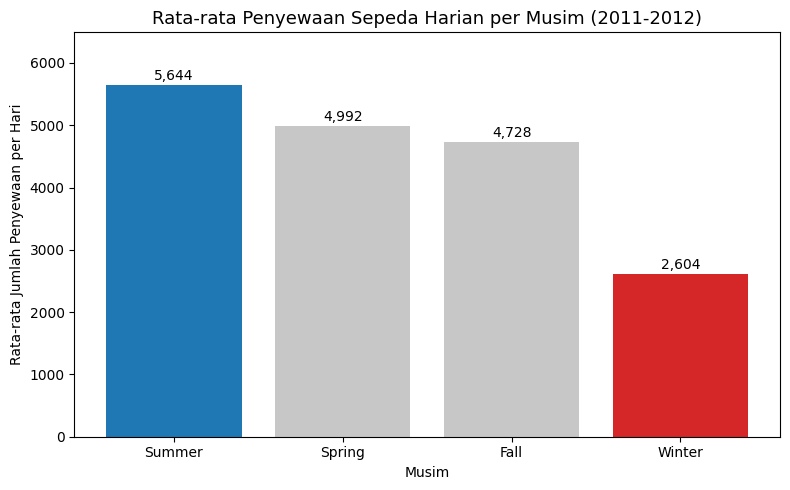

In [72]:
fig, ax = plt.subplots(figsize=(8, 5))

colors = ['#1f77b4' if s == season_df['mean'].idxmax()
          else '#d62728' if s == season_df['mean'].idxmin()
          else '#c7c7c7' for s in season_df.index]

ax.bar(season_df.index, season_df['mean'], color=colors)

for i, v in enumerate(season_df['mean']):
    ax.text(i, v + 80, f'{v:,.0f}', ha='center', fontsize=10)

ax.set_title('Rata-rata Penyewaan Sepeda Harian per Musim (2011-2012)', fontsize=13)
ax.set_xlabel('Musim')
ax.set_ylabel('Rata-rata Jumlah Penyewaan per Hari')
ax.set_ylim(0, season_df['mean'].max() * 1.15)
plt.tight_layout()
plt.show()

**Penjelasan grafik:** Diagram batang ini menunjukkan rata-rata jumlah penyewaan sepeda per hari pada setiap musim selama 2011-2012, diurutkan dari tertinggi. Summer (biru) memiliki rata-rata tertinggi sebesar 5.644 sepeda per hari, sedangkan Winter (merah) terendah sebesar 2.604. Spring (4.992) dan Fall (4.728) berada di antara keduanya dengan selisih yang tipis.

### Pertanyaan 2: Pada jam berapa rata-rata jumlah penyewaan sepeda per jam paling tinggi pada hari kerja dibandingkan hari libur selama periode 2011-2012, dan berapa selisih rata-ratanya, sehingga operator dapat menjadwalkan distribusi dan perawatan sepeda di luar jam sibuk?

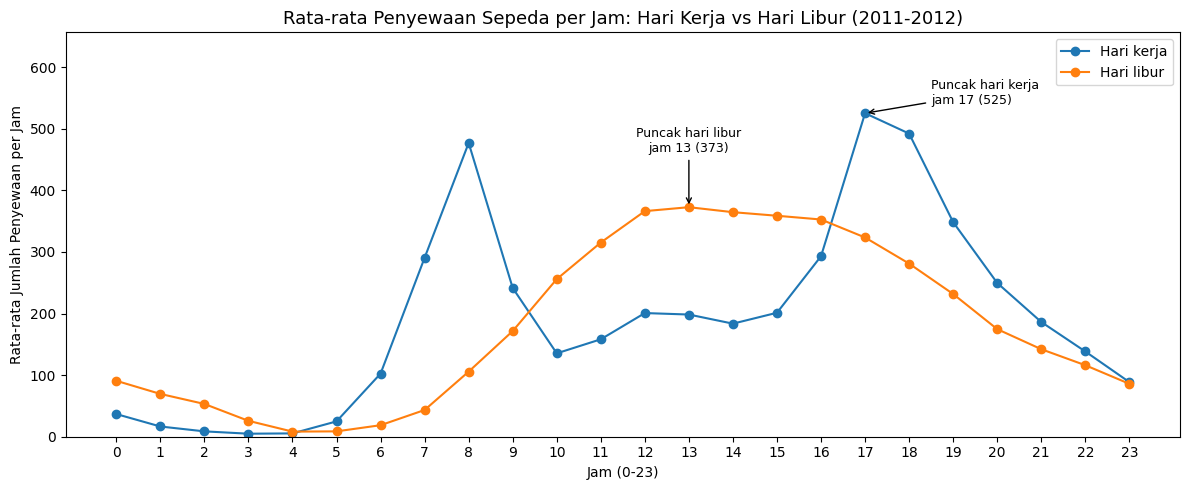

In [73]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(hourly_df.index, hourly_df['Working Day'], marker='o', color='#1f77b4', label='Hari kerja')
ax.plot(hourly_df.index, hourly_df['Non-Working Day'], marker='o', color='#ff7f0e', label='Hari libur')

peak_work = hourly_df['Working Day'].idxmax()
peak_off = hourly_df['Non-Working Day'].idxmax()

ax.annotate(f"Puncak hari kerja\njam {peak_work} ({hourly_df['Working Day'].max():,.0f})",
            xy=(peak_work, hourly_df['Working Day'].max()),
            xytext=(peak_work + 1.5, hourly_df['Working Day'].max() + 15),
            arrowprops=dict(arrowstyle='->'), fontsize=9)
ax.annotate(f"Puncak hari libur\njam {peak_off} ({hourly_df['Non-Working Day'].max():,.0f})",
            xy=(peak_off, hourly_df['Non-Working Day'].max()),
            xytext=(peak_off, hourly_df['Non-Working Day'].max() + 90),
            ha='center', arrowprops=dict(arrowstyle='->'), fontsize=9)

ax.set_title('Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Hari Libur (2011-2012)', fontsize=13)
ax.set_xlabel('Jam (0-23)')
ax.set_ylabel('Rata-rata Jumlah Penyewaan per Jam')
ax.set_xticks(range(0, 24))
ax.set_ylim(0, hourly_df['Working Day'].max() * 1.25)
ax.legend()
plt.tight_layout()
plt.show()

**Penjelasan grafik:** Grafik garis ini menunjukkan rata-rata jumlah penyewaan pada setiap jam (0-23) selama 2011-2012, dipisah antara hari kerja dan hari libur. Garis hari kerja memiliki dua puncak, yaitu pada jam 8 (477) dan jam 17 (525), sedangkan garis hari libur hanya memiliki satu puncak landai pada jam 13 (373).

**Insight:**
- Pada grafik musim, urutan permintaan adalah Summer, Spring, Fall, lalu Winter. Summer unggul sekitar 652 penyewaan per hari (sekitar 13%) dibandingkan Spring, sedangkan rata-rata Winter hanya sekitar 46% dari Summer, atau sekitar 54% lebih rendah.
- Pada hari kerja, penyewaan turun tajam setelah puncak pagi, dari 477 pada jam 8 menjadi 135 pada jam 10 (turun sekitar 72%), lalu bertahan stabil di kisaran 184-201 pada jam 12-15 sebelum naik lagi menjelang puncak sore.
- Kenaikan penyewaan pagi hari kerja sangat cepat: dari sekitar 5 pada jam 4 menjadi 477 pada jam 8, yaitu hanya empat jam. Pada hari libur, kenaikan dari sekitar 8 pada jam 4 menuju puncaknya (373 pada jam 13) berlangsung bertahap selama sembilan jam.
- Pada jam 0, penyewaan hari libur (sekitar 91) sekitar 2,5 kali hari kerja (sekitar 37), menandakan aktivitas malam hari libur masih berlanjut hingga dini hari.
- Menjelang akhir hari, kedua garis semakin berdekatan dan hampir bertemu pada jam 23 (88,7 pada hari kerja dan 85,9 pada hari libur).
- Variasi dalam satu hari jauh lebih besar daripada variasi antar musim. Rata-rata antar musim berbeda sekitar 2 kali lipat (Summer dibandingkan Winter), sedangkan pada hari kerja penyewaan jam 17 (525) lebih dari 100 kali penyewaan jam 3 (sekitar 5).

## Analisis Lanjutan (Opsional)

Analisis lanjutan memakai dua teknik analisis yaitu: **binning** pada suhu (Pertanyaan 1) dan **manual grouping** pada jam (Pertanyaan 2). Keduanya dipakai untuk melihat apakah pola musim berkaitan dengan suhu, dan bagaimana permintaan terbagi pada kelompok waktu tertentu.

**Tujuan:** melihat apakah perbedaan penyewaan antar musim berkaitan dengan suhu (Pertanyaan 1), dan pada kelompok waktu mana hari kerja dan hari libur memiliki pola penyewaan yang berbeda (Pertanyaan 2).

#### Binning suhu harian (tiga kategori: **Dingin** (di bawah 15 °C), **Sedang** (15-25 °C), dan **Panas** (di atas 25 °C)).

In [74]:
day_df['kategori_suhu'] = pd.cut(day_df['temp'], bins=[0, 15, 25, 40], labels=['Dingin', 'Sedang', 'Panas'])

In [75]:
day_df['kategori_suhu'].value_counts()

,count
kategori_suhu,
Sedang,268
Panas,242
Dingin,221


In [76]:
day_df.groupby('kategori_suhu', observed=True)['cnt'].mean().round(1)

,cnt
kategori_suhu,
Dingin,2833.3
Sedang,4864.0
Panas,5632.1


In [77]:
pd.crosstab(day_df['season'], day_df['kategori_suhu'])

kategori_suhu,Dingin,Sedang,Panas
season,,,
Fall,65,102,11
Spring,17,105,62
Summer,0,19,169
Winter,139,42,0


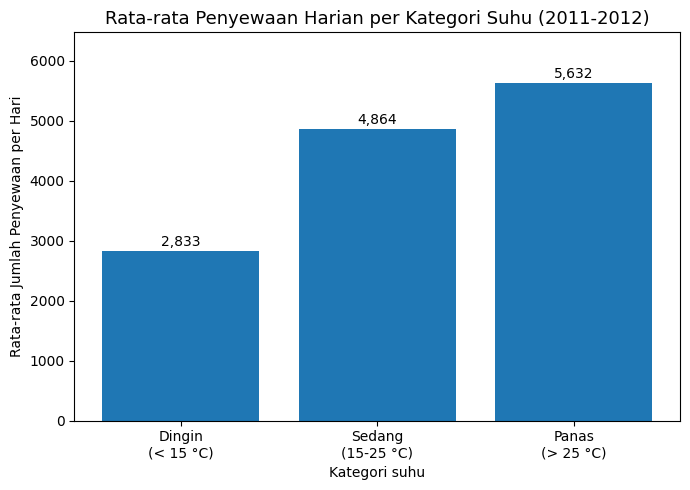

In [78]:
suhu_df = day_df.groupby('kategori_suhu', observed=True)['cnt'].mean().round(1)

label_suhu = {'Dingin': 'Dingin\n(< 15 °C)',
              'Sedang': 'Sedang\n(15-25 °C)',
              'Panas': 'Panas\n(> 25 °C)'}

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar([label_suhu[k] for k in suhu_df.index.astype(str)], suhu_df.values, color='#1f77b4')
for i, v in enumerate(suhu_df.values):
    ax.text(i, v + 80, f'{v:,.0f}', ha='center', fontsize=10)
ax.set_title('Rata-rata Penyewaan Harian per Kategori Suhu (2011-2012)', fontsize=13)
ax.set_xlabel('Kategori suhu')
ax.set_ylabel('Rata-rata Jumlah Penyewaan per Hari')
ax.set_ylim(0, suhu_df.max() * 1.15)
plt.tight_layout()
plt.show()

**Penjelasan grafik:** Diagram batang ini menunjukkan rata-rata jumlah penyewaan per hari pada tiga kategori suhu selama 2011-2012. Penyewaan meningkat seiring suhu: kategori Dingin (< 15 °C) memiliki rata-rata terendah sebesar 2.833, Sedang (15-25 °C) sebesar 4.864, dan Panas (> 25 °C) tertinggi sebesar 5.632. Kenaikan terbesar terjadi dari kategori Dingin ke Sedang, sedangkan dari Sedang ke Panas kenaikannya lebih kecil.

#### Pengelompokan jam (lima kelompok waktu: **Dini hari** (0-5), **Pagi** (6-9), **Siang** (10-15), **Sore** (16-19), dan **Malam** (20-23)).

In [79]:
hour_df['kelompok_waktu'] = pd.cut(hour_df['hr'], bins=[-1, 5, 9, 15, 19, 23],
                                   labels=['Dini hari', 'Pagi', 'Siang', 'Sore', 'Malam'])

In [80]:
hour_df['kelompok_waktu'].value_counts().sort_index()

,count
kelompok_waktu,
Dini hari,4276
Pagi,2906
Siang,4369
Sore,2916
Malam,2912


In [81]:
waktu_df = hour_df.pivot_table(index='kelompok_waktu', columns='workingday', values='cnt', aggfunc='mean', observed=True).round(1)

In [82]:
waktu_df

workingday,Non-Working Day,Working Day
kelompok_waktu,,
Dini hari,43.0,16.4
Pagi,85.0,277.9
Siang,338.9,179.7
Sore,297.3,414.8
Malam,129.7,165.8


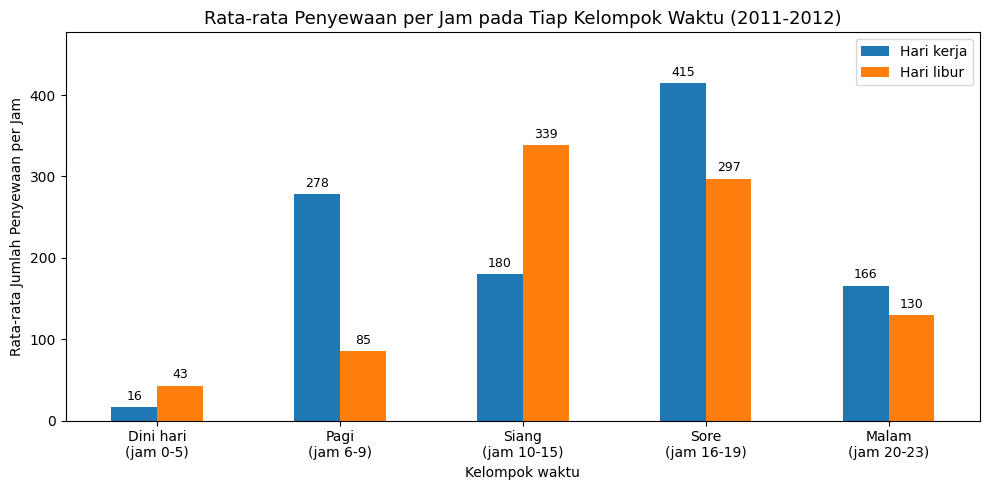

In [83]:
label_waktu = ['Dini hari\n(jam 0-5)', 'Pagi\n(jam 6-9)', 'Siang\n(jam 10-15)',
               'Sore\n(jam 16-19)', 'Malam\n(jam 20-23)']

fig, ax = plt.subplots(figsize=(10, 5))
waktu_df[['Working Day', 'Non-Working Day']].plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

ax.set_xticklabels(label_waktu, rotation=0)
ax.set_title('Rata-rata Penyewaan per Jam pada Tiap Kelompok Waktu (2011-2012)', fontsize=13)
ax.set_xlabel('Kelompok waktu')
ax.set_ylabel('Rata-rata Jumlah Penyewaan per Jam')
ax.set_ylim(0, waktu_df[['Working Day', 'Non-Working Day']].max().max() * 1.15)
ax.legend(['Hari kerja', 'Hari libur'])
plt.tight_layout()
plt.show()

**Penjelasan grafik:** Diagram batang berkelompok ini menunjukkan rata-rata jumlah penyewaan per jam pada lima kelompok waktu, dipisah antara hari kerja (biru) dan hari libur (oranye). Hari kerja lebih tinggi pada kelompok Pagi (jam 6-9) dan Sore (jam 16-19), dengan Sore sebagai yang tertinggi (415). Hari libur lebih tinggi pada kelompok Dini hari (jam 0-5) dan Siang (jam 10-15), dengan Siang sebagai yang tertinggi (sekitar 339). Pada kelompok Malam (jam 20-23), hari kerja masih sedikit lebih tinggi dibandingkan hari libur.

**Insight:**
- Pola penyewaan berdasarkan suhu sejalan dengan pola musim pada Pertanyaan 1. Rata-rata kategori Panas (5.632) hampir sama dengan Summer (5.644), dan kategori Dingin (2.833) berada dekat dengan Winter (2.604). Ini menunjukkan perbedaan antar musim kemungkinan besar berkaitan dengan suhu.
- Peningkatan suhu tidak menaikkan penyewaan secara merata. Dari Dingin ke Sedang penyewaan naik sekitar 72% (2.833 menjadi 4.864), sedangkan dari Sedang ke Panas hanya naik sekitar 16% (4.864 menjadi 5.632). Pengaruh suhu terlihat paling besar saat keluar dari kondisi dingin, lalu melandai pada suhu yang sudah nyaman.
- Hari kerja dan hari libur punya kelompok waktu andalan yang berbeda. Pada hari kerja, penyewaan paling tinggi ada di Sore dan Pagi, sedangkan pada hari libur paling tinggi di Siang dan Sore. Kelompok Pagi memperlihatkan jurang terbesar: penyewaan hari kerja sekitar tiga kali hari libur.
- Hari libur mengungguli hari kerja pada dua kelompok yang berlawanan, yaitu Dini hari dan Siang. Pada dini hari, penyewaan hari libur sekitar dua setengah kali hari kerja, meskipun nilainya kecil dibandingkan kelompok lain.
- Kelompok Sore pada hari kerja adalah yang tertinggi dari seluruh kelompok waktu, sedangkan Dini hari menjadi yang terendah pada kedua jenis hari.
- Rata-rata kelompok Sore hari kerja (sekitar 415) lebih rendah dari puncak jam 17 pada grafik Pertanyaan 2 (525), karena kelompok ini juga memuat jam yang lebih sepi (jam 16 dan 19). Pengelompokan meratakan puncak, tetapi urutan antar kelompok tetap sejalan dengan pola per jam.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama 2011-2012, rata-rata penyewaan harian tertinggi terjadi pada musim **Summer** sebesar 5.644 penyewaan per hari, dan terendah pada musim **Winter** sebesar 2.604 penyewaan per hari. Selisih rata-ratanya adalah **3.040 penyewaan per hari**, sehingga penyewaan pada Summer sekitar 2,2 kali lipat Winter. Spring (4.992) dan Fall (4.728) berada di antara keduanya.

- **Conclusion pertanyaan 2:** Pada hari kerja, rata-rata penyewaan per jam tertinggi terjadi pada **jam 17** sebesar 525 penyewaan, sedangkan pada hari libur tertinggi terjadi pada **jam 13** sebesar 373 penyewaan. Puncak hari kerja lebih tinggi **153 penyewaan per jam** dibandingkan puncak hari libur. Hari kerja juga memiliki puncak kedua pada jam 8 (477), sedangkan hari libur hanya memiliki satu puncak landai di tengah hari.

- **Kesimpulan tambahan (analisis lanjutan):** Penyewaan meningkat seiring suhu, dari 2.833 per hari pada kategori Dingin (< 15 °C), menjadi 4.864 pada Sedang (15-25 °C), dan 5.632 pada Panas (> 25 °C). Pada pengelompokan jam, Hari kerja unggul pada kelompok Pagi (jam 6-9) dan Sore (jam 16-19), dengan Sore sebagai yang tertinggi (sebanyak 415 penyewaan per jam). Hari libur unggul pada kelompok Siang (jam 10-15), yaitu sekitar 339 penyewaan per jam, serta pada Dini hari (jam 0-5). Kelompok Pagi menunjukkan selisih terbesar, karena penyewaan hari kerja (278) sekitar tiga kali hari libur (85)

**Rekomendasi Action Item:**
- Siapkan jumlah sepeda terbanyak pada musim Summer, dan kurangi sepeda yang beroperasi pada musim Winter (permintaan Winter sekitar 46% dari Summer). Jadwalkan perawatan besar armada pada Winter agar sepeda siap sebelum Spring.
- Pada hari kerja, pastikan sepeda sudah terdistribusi ke titik-titik ramai sebelum jam 8 dan sebelum jam 17, karena kedua jam tersebut adalah puncak penyewaan. Pada hari libur, pindahkan fokus distribusi dan kapasitas ke tengah hari (jam 11-15), dan jangan memakai jadwal yang sama dengan hari kerja. Jadwalkan perawatan dan penataan ulang sepeda pada jam 3-5, karena penyewaan pada jam tersebut paling sepi di kedua jenis hari (di bawah 10 penyewaan per jam).
- Gunakan prakiraan suhu harian untuk menyesuaikan armada: tambah jumlah sepeda pada hari bersuhu di atas 15 °C (kategori Sedang dan Panas), dan kurangi pada hari di bawah 15 °C (kategori Dingin), karena kenaikan penyewaan terbesar terjadi saat suhu melewati batas tersebut (dari 2.833 menjadi 4.864 penyewaan per hari).
- Pada hari kerja, tambah sepeda yang disiagakan pada kelompok Sore (jam 16-19), karena merupakan kelompok dengan penyewaan tertinggi dari seluruh kelompok waktu. Pada hari libur, alihkan kapasitas armada ke kelompok Siang (jam 10-15), karena penyewaannya jauh lebih tinggi dibandingkan hari kerja pada kelompok yang sama. Jadwalkan perawatan serta penataan ulang sepeda pada kelompok Dini hari (jam 0-5) saat penyewaan paling rendah pada hari libur maupun hari kerja.